In [1]:

import pandas as pd

# 1. Load the three anomaly datasets
ndvi = pd.read_csv("NDVI_Anomalies_2005_2025.csv")
rain = pd.read_csv("IMD_Rainfall_Anomalies.csv")
temp = pd.read_csv("ERA5_Temperature_Anomalies.csv")

In [2]:
# 2. Align rainfall with the PREVIOUS monsoon year
# Example: NDVI in 2005 <- monsoon rainfall in 2004
rain_aligned = rain[[
    "Year",
    "Monsoon_Rainfall_Anomaly_mm",
    "Annual_Rainfall_Anomaly_mm"
]].copy()

rain_aligned = rain_aligned.rename(columns={
    "Year": "Monsoon_Year",
    "Monsoon_Rainfall_Anomaly_mm":
        "Previous_Monsoon_Rainfall_Anomaly_mm",
    "Annual_Rainfall_Anomaly_mm":
        "Previous_Annual_Rainfall_Anomaly_mm"
})

# Shift rainfall year forward to the corresponding NDVI year
rain_aligned["Year"] = rain_aligned["Monsoon_Year"] + 1

In [3]:
# 3. Prepare temperature anomalies
# January–February temperature: same year as NDVI
# Annual temperature: use the previous year's value
temp_aligned = temp[[
    "Year",
    "Annual_Temperature_Anomaly_C",
    "Jan_Feb_Temperature_Anomaly_C"
]].copy()

temp_aligned = temp_aligned.rename(columns={
    "Year": "Temperature_Year",
    "Annual_Temperature_Anomaly_C":
        "Previous_Annual_Temperature_Anomaly_C",
    "Jan_Feb_Temperature_Anomaly_C":
        "Jan_Feb_Temperature_Anomaly_C"
})

# Create a previous-year annual temperature indicator
temp_aligned["Year"] = temp_aligned["Temperature_Year"] + 1

# Shift January–February temperature back to its actual observation year
# so it can be merged with NDVI from the same year
temp_same_year = temp[[
    "Year",
    "Jan_Feb_Temperature_Anomaly_C"
]].copy()

In [4]:
# 4. Merge NDVI with previous-year rainfall
combined = ndvi.merge(
    rain_aligned.drop(columns=["Monsoon_Year"]),
    on="Year",
    how="left"
)

In [5]:
# 5. Add previous-year annual temperature anomaly
combined = combined.merge(
    temp_aligned[[
        "Year",
        "Previous_Annual_Temperature_Anomaly_C"
    ]],
    on="Year",
    how="left"
)

In [6]:
# 6. Add same-year January–February temperature anomaly
combined = combined.merge(
    temp_same_year,
    on="Year",
    how="left"
)

In [7]:
# 7. Keep analysis period
combined = combined[
    (combined["Year"] >= 2005) &
    (combined["Year"] <= 2025)
].sort_values("Year")

In [8]:
# 8. Check alignment and missing values
print("Combined dataset shape:", combined.shape)
print("\nMissing values:")
print(combined.isnull().sum())

print("\nPreview:")
print(combined.head())

Combined dataset shape: (21, 9)

Missing values:
Year                                     0
0–1 km zone anomaly                      0
1–3 km zone anomaly                      0
3–5 km zone anomaly                      0
Overall anomaly                          0
Previous_Monsoon_Rainfall_Anomaly_mm     0
Previous_Annual_Rainfall_Anomaly_mm      0
Previous_Annual_Temperature_Anomaly_C    0
Jan_Feb_Temperature_Anomaly_C            0
dtype: int64

Preview:
   Year  0–1 km zone anomaly  1–3 km zone anomaly  3–5 km zone anomaly  \
0  2005            -0.010618            -0.010028            -0.013590   
1  2006            -0.012528            -0.015955            -0.019847   
2  2007            -0.015810            -0.018678            -0.020679   
3  2008            -0.027467            -0.024664            -0.026748   
4  2009            -0.033284            -0.029850            -0.033111   

   Overall anomaly  Previous_Monsoon_Rainfall_Anomaly_mm  \
0        -0.011412                  

In [9]:
# 9. Save final aligned dataset
combined.to_csv(
    "Combined_NDVI_Climate_Anomalies_2005_2025.csv",
    index=False
)

print("\nSaved: Combined_NDVI_Climate_Anomalies_2005_2025.csv")



Saved: Combined_NDVI_Climate_Anomalies_2005_2025.csv


In [10]:
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the combined dataset
data = pd.read_csv(
    "Combined_NDVI_Climate_Anomalies_2005_2025.csv"
)

In [11]:
# 2. Define NDVI anomaly columns for each zone
zones = {
    "0–1 km": "0–1 km zone anomaly",
    "1–3 km": "1–3 km zone anomaly",
    "3–5 km": "3–5 km zone anomaly"
}

In [12]:

# 3. Define climate anomaly columns
climate_variables = {
    "Previous Monsoon Rainfall":
        "Previous_Monsoon_Rainfall_Anomaly_mm",

    "Previous Annual Rainfall":
        "Previous_Annual_Rainfall_Anomaly_mm",

    "Previous Annual Temperature":
        "Previous_Annual_Temperature_Anomaly_C",

    "January–February Temperature":
        "Jan_Feb_Temperature_Anomaly_C"
}

In [13]:

# 4. Calculate Pearson correlation
results = []

for zone, ndvi_col in zones.items():

    for climate_name, climate_col in climate_variables.items():

        subset = data[[ndvi_col, climate_col]].dropna()

        r, p_value = pearsonr(
            subset[ndvi_col],
            subset[climate_col]
        )

        # Interpret correlation strength
        abs_r = abs(r)

        if abs_r < 0.20:
            strength = "Very weak"
        elif abs_r < 0.40:
            strength = "Weak"
        elif abs_r < 0.60:
            strength = "Moderate"
        elif abs_r < 0.80:
            strength = "Strong"
        else:
            strength = "Very strong"

        if p_value < 0.05:
            significance = "Statistically significant"
        else:
            significance = "Not statistically significant"

        results.append({
            "Zone": zone,
            "Climate Variable": climate_name,
            "Sample Size": len(subset),
            "Pearson_r": r,
            "P_value": p_value,
            "Strength": strength,
            "Significance": significance
        })

In [14]:
# 5. Create results table
results_df = pd.DataFrame(results)

print("\nPEARSON CORRELATION RESULTS\n")
print(results_df.round(4).to_string(index=False))



PEARSON CORRELATION RESULTS

  Zone             Climate Variable  Sample Size  Pearson_r  P_value  Strength                  Significance
0–1 km    Previous Monsoon Rainfall           21     0.3308   0.1430      Weak Not statistically significant
0–1 km     Previous Annual Rainfall           21     0.3102   0.1711      Weak Not statistically significant
0–1 km  Previous Annual Temperature           21     0.0453   0.8453 Very weak Not statistically significant
0–1 km January–February Temperature           21    -0.2835   0.2130      Weak Not statistically significant
1–3 km    Previous Monsoon Rainfall           21     0.3479   0.1223      Weak Not statistically significant
1–3 km     Previous Annual Rainfall           21     0.3197   0.1578      Weak Not statistically significant
1–3 km  Previous Annual Temperature           21     0.0539   0.8165 Very weak Not statistically significant
1–3 km January–February Temperature           21    -0.1553   0.5016 Very weak Not statistically s

In [15]:
# 6. Save results
results_df.to_csv(
    "Pearson_Correlation_Results.csv",
    index=False
)

print("\nSaved: Pearson_Correlation_Results.csv")


Saved: Pearson_Correlation_Results.csv


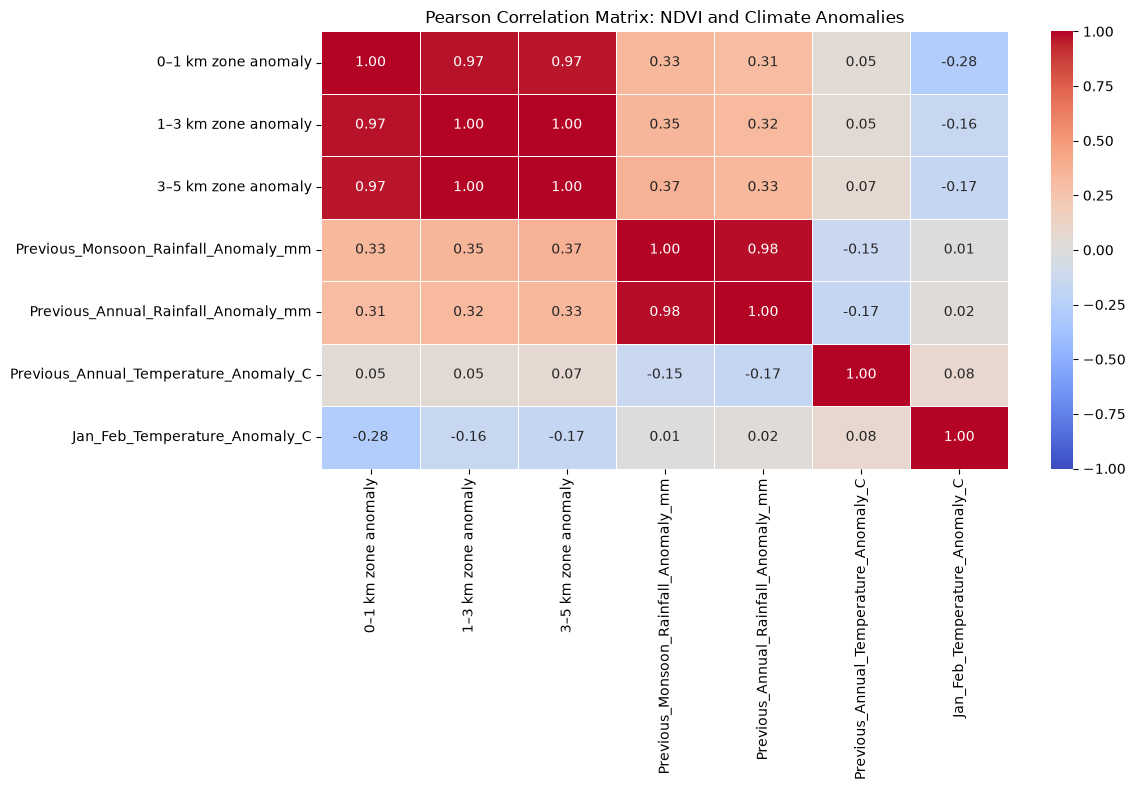

In [16]:
# 7. Create a correlation matrix for visualization
correlation_data = data[
    list(zones.values()) + list(climate_variables.values())
]

correlation_matrix = correlation_data.corr(method="pearson")

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix: NDVI and Climate Anomalies")
plt.tight_layout()
plt.show()


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# ============================================================
# 1. LOAD DATA
# ============================================================

ndvi_climate = pd.read_csv(
    "Combined_NDVI_Climate_Anomalies_2005_2025.csv"
)

sccl = pd.read_csv(
    "SCCL_production_2005-2025.csv"
)

# Remove spaces from column names
ndvi_climate.columns = ndvi_climate.columns.str.strip()
sccl.columns = sccl.columns.str.strip()


In [18]:

# ============================================================
# 2. PREPARE NDVI DATA
# ============================================================

ndvi_climate["Year"] = pd.to_numeric(
    ndvi_climate["Year"], errors="coerce"
)

ndvi_climate = ndvi_climate.dropna(subset=["Year"]).copy()
ndvi_climate["Year"] = ndvi_climate["Year"].astype(int)

In [19]:

# ============================================================
# 3. PREPARE SCCL DATA
# ============================================================

# Extract starting year from Financial_Year, e.g. 2005-06 -> 2005
sccl["FY_Start_Year"] = pd.to_numeric(
    sccl["Financial_Year"]
    .astype(str)
    .str.extract(r"(\d{4})")[0],
    errors="coerce"
)

sccl = sccl.dropna(subset=["FY_Start_Year"]).copy()
sccl["FY_Start_Year"] = sccl["FY_Start_Year"].astype(int)

# Assign FY 2005-06 to calendar year 2006
sccl["NDVI_Year"] = sccl["FY_Start_Year"] + 1

# Rename production columns
sccl = sccl.rename(columns={
    "Open_Cast_Lakh_Tonnes": "Open_Cast_Production",
    "Underground_Lakh_Tonnes": "Underground_Production",
    "Total_Production_Lakh_Tonnes": "Total_Production"
})

production_vars = [
    "Open_Cast_Production",
    "Underground_Production",
    "Total_Production"
]

# Convert production values to numeric
for col in production_vars:
    sccl[col] = pd.to_numeric(sccl[col], errors="coerce")

In [20]:

# ============================================================
# 4. MERGE DATASETS
# ============================================================

sccl_selected = sccl[
    [
        "NDVI_Year",
        "Financial_Year",
        "Open_Cast_Production",
        "Underground_Production",
        "Total_Production"
    ]
]

merged = pd.merge(
    ndvi_climate,
    sccl_selected,
    left_on="Year",
    right_on="NDVI_Year",
    how="inner",
    validate="one_to_one"
)

merged = merged.drop(columns=["NDVI_Year"])
merged = merged.sort_values("Year").reset_index(drop=True)

print("Merged dataset shape:", merged.shape)
print("\nMatched years:")
print(merged[["Year", "Financial_Year"]].to_string(index=False))

print("\nMissing values:")
print(merged.isnull().sum())

Merged dataset shape: (21, 13)

Matched years:
 Year Financial_Year
 2005        2004-05
 2006        2005-06
 2007        2006-07
 2008        2007-08
 2009        2008-09
 2010        2009-10
 2011        2010-11
 2012        2011-12
 2013        2012-13
 2014        2013-14
 2015        2014-15
 2016        2015-16
 2017        2016-17
 2018        2017-18
 2019        2018-19
 2020        2019-20
 2021        2020-21
 2022        2021-22
 2023        2022-23
 2024        2023-24
 2025        2024-25

Missing values:
Year                                     0
0–1 km zone anomaly                      0
1–3 km zone anomaly                      0
3–5 km zone anomaly                      0
Overall anomaly                          0
Previous_Monsoon_Rainfall_Anomaly_mm     0
Previous_Annual_Rainfall_Anomaly_mm      0
Previous_Annual_Temperature_Anomaly_C    0
Jan_Feb_Temperature_Anomaly_C            0
Financial_Year                           0
Open_Cast_Production                     0
U

In [21]:

# Save merged data
merged.to_csv("NDVI_Climate_SCCL_Merged.csv", index=False)

# ============================================================
# 5. DEFINE VARIABLES
# ============================================================

ndvi_zones = [
    "0–1 km zone anomaly",
    "1–3 km zone anomaly",
    "3–5 km zone anomaly"
]

climate_vars = [
    "Previous_Monsoon_Rainfall_Anomaly_mm",
    "Previous_Annual_Rainfall_Anomaly_mm",
    "Previous_Annual_Temperature_Anomaly_C",
    "Jan_Feb_Temperature_Anomaly_C"
]

In [22]:

# ============================================================
# 6. PEARSON AND SPEARMAN CORRELATION
#    NDVI vs SCCL production
# ============================================================

results = []

for zone in ndvi_zones:
    for production in production_vars:

        pair = merged[[zone, production]].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        x = pair[zone]
        y = pair[production]

        if len(pair) < 3 or x.nunique() < 2 or y.nunique() < 2:
            pearson_r, pearson_p = np.nan, np.nan
            spearman_rho, spearman_p = np.nan, np.nan
        else:
            pearson_r, pearson_p = pearsonr(x, y)
            spearman_rho, spearman_p = spearmanr(x, y)

        results.append({
            "NDVI_Zone": zone,
            "Production_Type": production,
            "N": len(pair),
            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_rho": spearman_rho,
            "Spearman_p": spearman_p
        })

correlation_results = pd.DataFrame(results)

print("\nSCCL PRODUCTION vs NDVI CORRELATIONS")
print(correlation_results.round(4).to_string(index=False))

correlation_results.to_csv(
    "SCCL_NDVI_Correlation_Results.csv",
    index=False
)


SCCL PRODUCTION vs NDVI CORRELATIONS
          NDVI_Zone        Production_Type  N  Pearson_r  Pearson_p  Spearman_rho  Spearman_p
0–1 km zone anomaly   Open_Cast_Production 21     0.7033     0.0004        0.7182      0.0002
0–1 km zone anomaly Underground_Production 21    -0.6924     0.0005       -0.7470      0.0001
0–1 km zone anomaly       Total_Production 21     0.6753     0.0008        0.6535      0.0013
1–3 km zone anomaly   Open_Cast_Production 21     0.7354     0.0001        0.7636      0.0001
1–3 km zone anomaly Underground_Production 21    -0.7317     0.0002       -0.7970      0.0000
1–3 km zone anomaly       Total_Production 21     0.7045     0.0004        0.6885      0.0006
3–5 km zone anomaly   Open_Cast_Production 21     0.7638     0.0001        0.8039      0.0000
3–5 km zone anomaly Underground_Production 21    -0.7585     0.0001       -0.8327      0.0000
3–5 km zone anomaly       Total_Production 21     0.7316     0.0002        0.7308      0.0002


In [23]:

# ============================================================
# 7. NDVI vs CLIMATE CORRELATION
# ============================================================

climate_results = []

for zone in ndvi_zones:
    for climate in climate_vars:

        pair = merged[[zone, climate]].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        x = pair[zone]
        y = pair[climate]

        if len(pair) < 3 or x.nunique() < 2 or y.nunique() < 2:
            r, p = np.nan, np.nan
            rho, p_spearman = np.nan, np.nan
        else:
            r, p = pearsonr(x, y)
            rho, p_spearman = spearmanr(x, y)

        climate_results.append({
            "NDVI_Zone": zone,
            "Climate_Variable": climate,
            "N": len(pair),
            "Pearson_r": r,
            "Pearson_p": p,
            "Spearman_rho": rho,
            "Spearman_p": p_spearman
        })

climate_results = pd.DataFrame(climate_results)

print("\nNDVI vs CLIMATE CORRELATIONS")
print(climate_results.round(4).to_string(index=False))

climate_results.to_csv(
    "NDVI_Climate_Correlation_Results.csv",
    index=False
)


NDVI vs CLIMATE CORRELATIONS
          NDVI_Zone                      Climate_Variable  N  Pearson_r  Pearson_p  Spearman_rho  Spearman_p
0–1 km zone anomaly  Previous_Monsoon_Rainfall_Anomaly_mm 21     0.3308     0.1430        0.2610      0.2531
0–1 km zone anomaly   Previous_Annual_Rainfall_Anomaly_mm 21     0.3102     0.1711        0.2455      0.2835
0–1 km zone anomaly Previous_Annual_Temperature_Anomaly_C 21     0.0453     0.8453        0.1052      0.6500
0–1 km zone anomaly         Jan_Feb_Temperature_Anomaly_C 21    -0.2835     0.2130       -0.2948      0.1945
1–3 km zone anomaly  Previous_Monsoon_Rainfall_Anomaly_mm 21     0.3479     0.1223        0.3182      0.1598
1–3 km zone anomaly   Previous_Annual_Rainfall_Anomaly_mm 21     0.3197     0.1578        0.3143      0.1653
1–3 km zone anomaly Previous_Annual_Temperature_Anomaly_C 21     0.0539     0.8165        0.0766      0.7413
1–3 km zone anomaly         Jan_Feb_Temperature_Anomaly_C 21    -0.1553     0.5016       -0.1481  

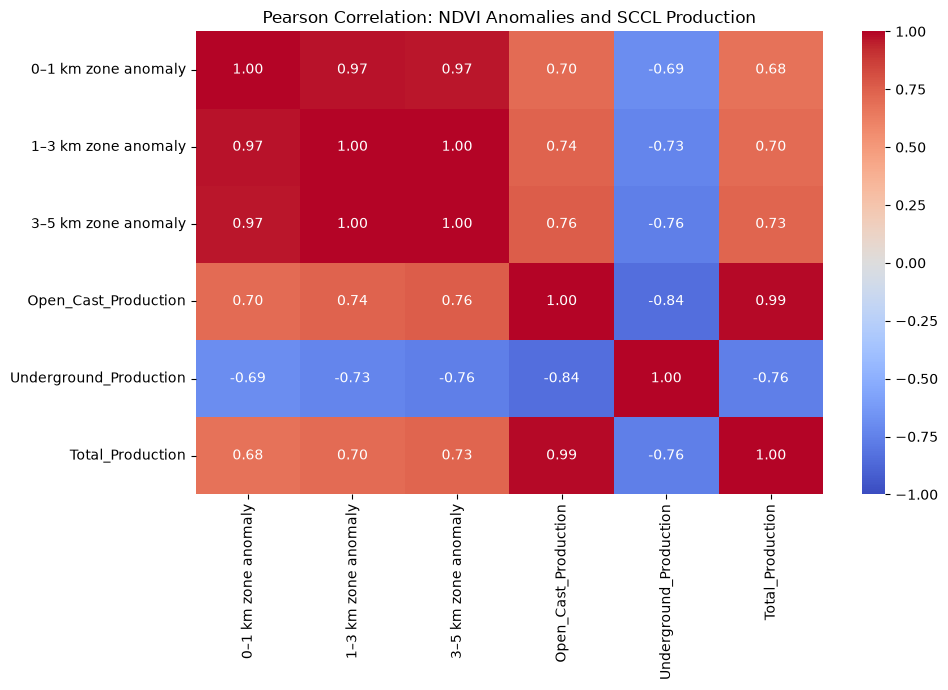

In [24]:

# ============================================================
# 8. HEATMAP: NDVI ZONES vs PRODUCTION VARIABLES
# ============================================================

# Select the six variables of interest
heatmap_data = merged[ndvi_zones + production_vars]

correlation_matrix = heatmap_data.corr(method="pearson")

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Pearson Correlation: NDVI Anomalies and SCCL Production")
plt.tight_layout()
plt.savefig("SCCL_NDVI_Correlation_Heatmap.png", dpi=300)
plt.show()


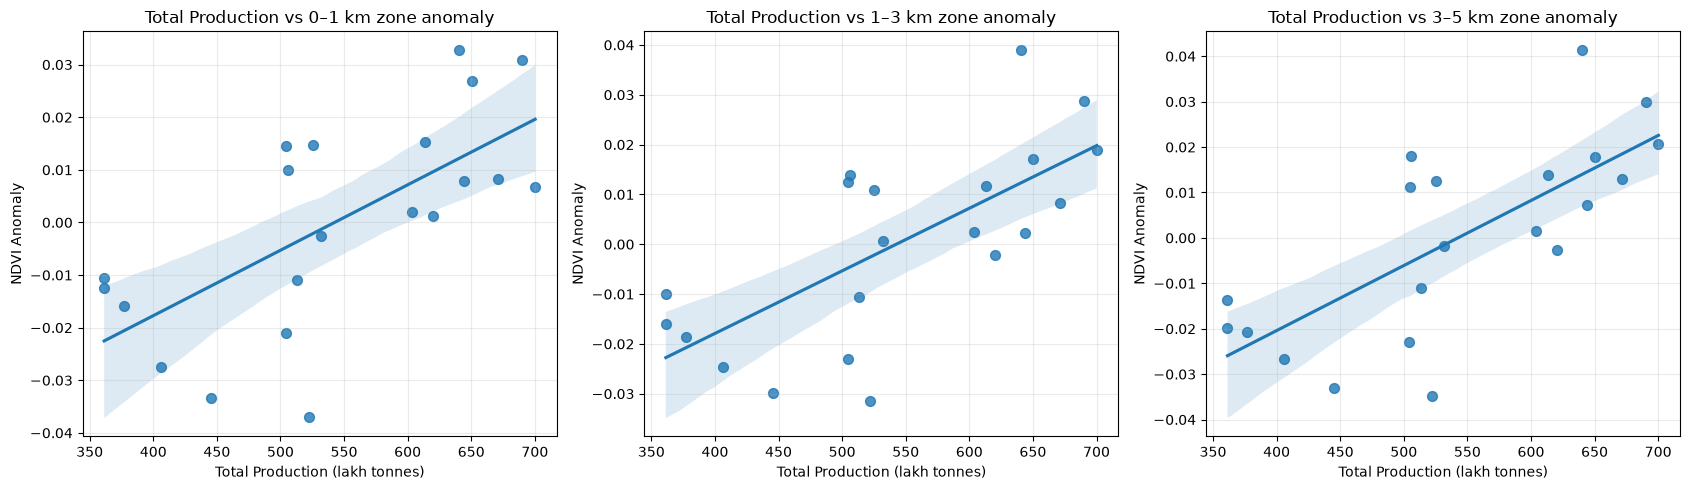

In [25]:

# ============================================================
# 9. SCATTER PLOTS: TOTAL PRODUCTION vs NDVI ANOMALIES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, zone in zip(axes, ndvi_zones):

    sns.regplot(
        data=merged,
        x="Total_Production",
        y=zone,
        ax=ax,
        ci=95,
        scatter_kws={"s": 50}
    )

    ax.set_title(f"Total Production vs {zone}")
    ax.set_xlabel("Total Production (lakh tonnes)")
    ax.set_ylabel("NDVI Anomaly")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("SCCL_Total_Production_vs_NDVI.png", dpi=300)
plt.show()

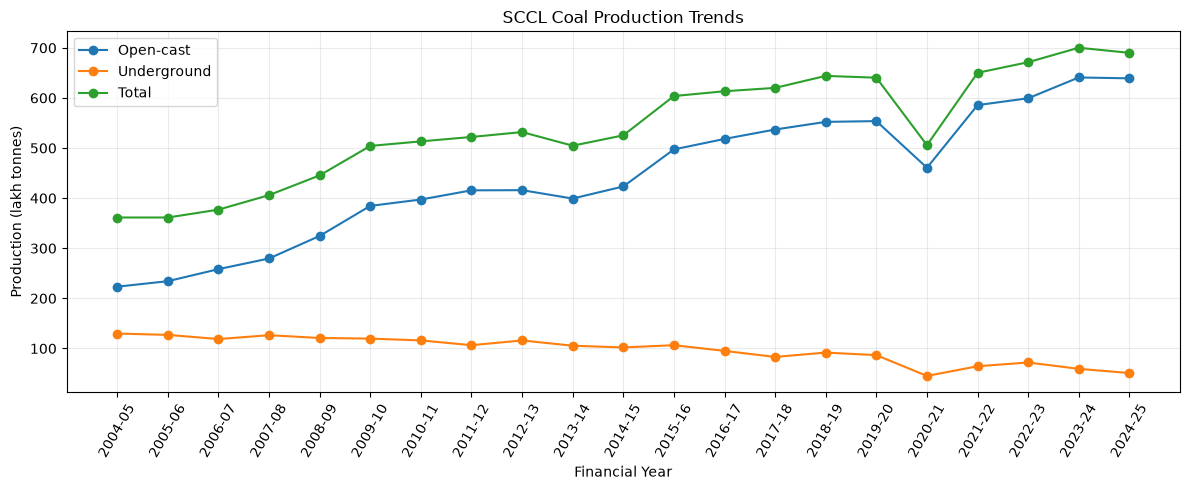

In [26]:

# ============================================================
# 10. SCCL PRODUCTION TREND
# ============================================================

sccl_plot = sccl.sort_values("FY_Start_Year")

plt.figure(figsize=(12, 5))

for col, label in [
    ("Open_Cast_Production", "Open-cast"),
    ("Underground_Production", "Underground"),
    ("Total_Production", "Total")
]:
    plt.plot(
        sccl_plot["Financial_Year"],
        sccl_plot[col],
        marker="o",
        label=label
    )

plt.xlabel("Financial Year")
plt.ylabel("Production (lakh tonnes)")
plt.title("SCCL Coal Production Trends")
plt.xticks(rotation=60)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("SCCL_Production_Trends.png", dpi=300)
plt.show()

In [27]:

# ============================================================
# 11. COMPLETED
# ============================================================

print("\nAnalysis completed. Files saved:")
print("1. NDVI_Climate_SCCL_Merged.csv")
print("2. SCCL_NDVI_Correlation_Results.csv")
print("3. NDVI_Climate_Correlation_Results.csv")
print("4. SCCL_NDVI_Correlation_Heatmap.png")
print("5. SCCL_Total_Production_vs_NDVI.png")
print("6. SCCL_Production_Trends.png")



Analysis completed. Files saved:
1. NDVI_Climate_SCCL_Merged.csv
2. SCCL_NDVI_Correlation_Results.csv
3. NDVI_Climate_Correlation_Results.csv
4. SCCL_NDVI_Correlation_Heatmap.png
5. SCCL_Total_Production_vs_NDVI.png
6. SCCL_Production_Trends.png


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. LOAD MERGED DATA
# ============================================================

df = pd.read_csv("NDVI_Climate_SCCL_Merged.csv")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

Dataset shape: (21, 13)

Available columns:
['Year', '0–1 km zone anomaly', '1–3 km zone anomaly', '3–5 km zone anomaly', 'Overall anomaly', 'Previous_Monsoon_Rainfall_Anomaly_mm', 'Previous_Annual_Rainfall_Anomaly_mm', 'Previous_Annual_Temperature_Anomaly_C', 'Jan_Feb_Temperature_Anomaly_C', 'Financial_Year', 'Open_Cast_Production', 'Underground_Production', 'Total_Production']


In [29]:

# ============================================================
# 2. SELECT ALL VARIABLES FOR CORRELATION
# ============================================================

variables = [
    # Vegetation / NDVI anomalies
    "0–1 km zone anomaly",
    "1–3 km zone anomaly",
    "3–5 km zone anomaly",
    "Overall anomaly",

    # Rainfall anomalies
    "Previous_Monsoon_Rainfall_Anomaly_mm",
    "Previous_Annual_Rainfall_Anomaly_mm",

    # Temperature anomalies
    "Previous_Annual_Temperature_Anomaly_C",
    "Jan_Feb_Temperature_Anomaly_C",

    # SCCL mining production
    "Open_Cast_Production",
    "Underground_Production",
    "Total_Production"
]

# Verify that all selected columns exist
missing = [col for col in variables if col not in df.columns]

if missing:
    raise ValueError(
        f"These columns are missing from the merged dataset: {missing}"
    )

# Convert selected columns to numeric
data = df[variables].apply(pd.to_numeric, errors="coerce")

print("\nMissing values in selected variables:")
print(data.isnull().sum())


Missing values in selected variables:
0–1 km zone anomaly                      0
1–3 km zone anomaly                      0
3–5 km zone anomaly                      0
Overall anomaly                          0
Previous_Monsoon_Rainfall_Anomaly_mm     0
Previous_Annual_Rainfall_Anomaly_mm      0
Previous_Annual_Temperature_Anomaly_C    0
Jan_Feb_Temperature_Anomaly_C            0
Open_Cast_Production                     0
Underground_Production                   0
Total_Production                         0
dtype: int64


In [30]:

# ============================================================
# 3. CALCULATE PEARSON CORRELATION MATRIX
# ============================================================

correlation_matrix = data.corr(method="pearson")

print("\nFULL PEARSON CORRELATION MATRIX:")
print(correlation_matrix.round(3).to_string())

# Save numerical matrix
correlation_matrix.to_csv(
    "Complete_Pearson_Correlation_Matrix.csv"
)


FULL PEARSON CORRELATION MATRIX:
                                       0–1 km zone anomaly  1–3 km zone anomaly  3–5 km zone anomaly  Overall anomaly  Previous_Monsoon_Rainfall_Anomaly_mm  Previous_Annual_Rainfall_Anomaly_mm  Previous_Annual_Temperature_Anomaly_C  Jan_Feb_Temperature_Anomaly_C  Open_Cast_Production  Underground_Production  Total_Production
0–1 km zone anomaly                                  1.000                0.970                0.969            0.987                                 0.331                                0.310                                  0.045                         -0.284                 0.703                  -0.692             0.675
1–3 km zone anomaly                                  0.970                1.000                0.995            0.996                                 0.348                                0.320                                  0.054                         -0.155                 0.735                  -0.732    

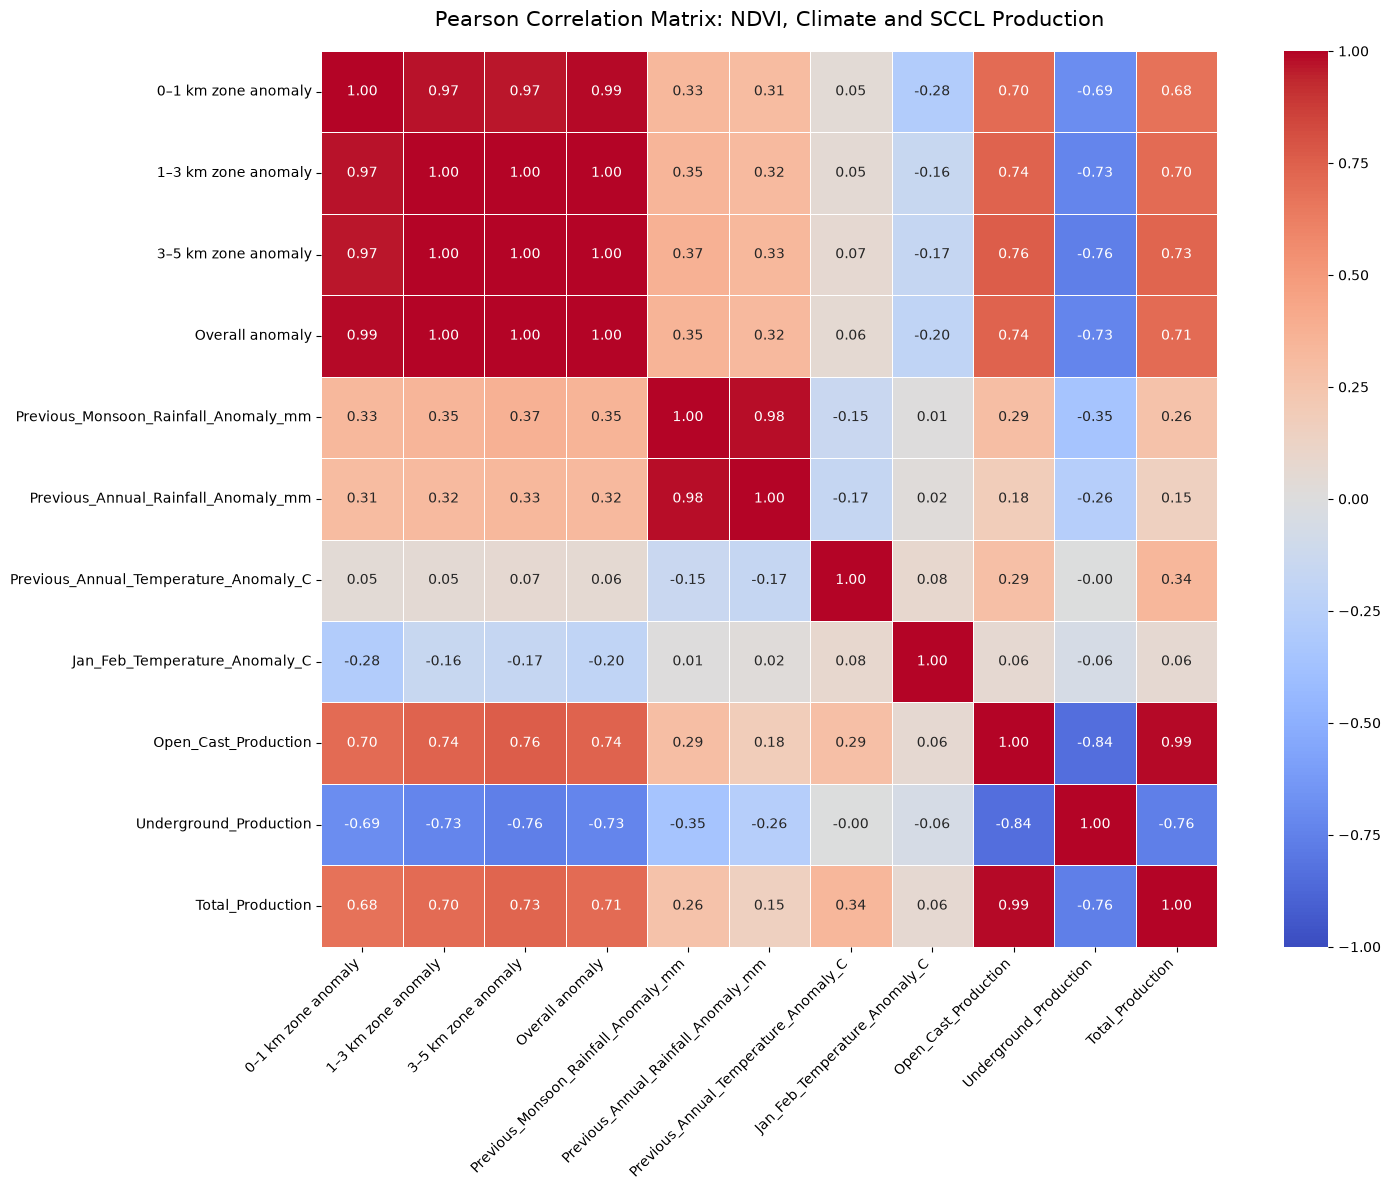

In [31]:

# ============================================================
# 4. DRAW COMPLETE CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Pearson Correlation Matrix: NDVI, Climate and SCCL Production",
    fontsize=15,
    pad=18
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "Complete_Pearson_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


NDVI vs CLIMATE AND MINING CORRELATIONS:
                     Previous_Monsoon_Rainfall_Anomaly_mm  Previous_Annual_Rainfall_Anomaly_mm  Previous_Annual_Temperature_Anomaly_C  Jan_Feb_Temperature_Anomaly_C  Open_Cast_Production  Underground_Production  Total_Production
0–1 km zone anomaly                                 0.331                                0.310                                  0.045                         -0.284                 0.703                  -0.692             0.675
1–3 km zone anomaly                                 0.348                                0.320                                  0.054                         -0.155                 0.735                  -0.732             0.704
3–5 km zone anomaly                                 0.369                                0.334                                  0.070                         -0.166                 0.764                  -0.758             0.732
Overall anomaly                           

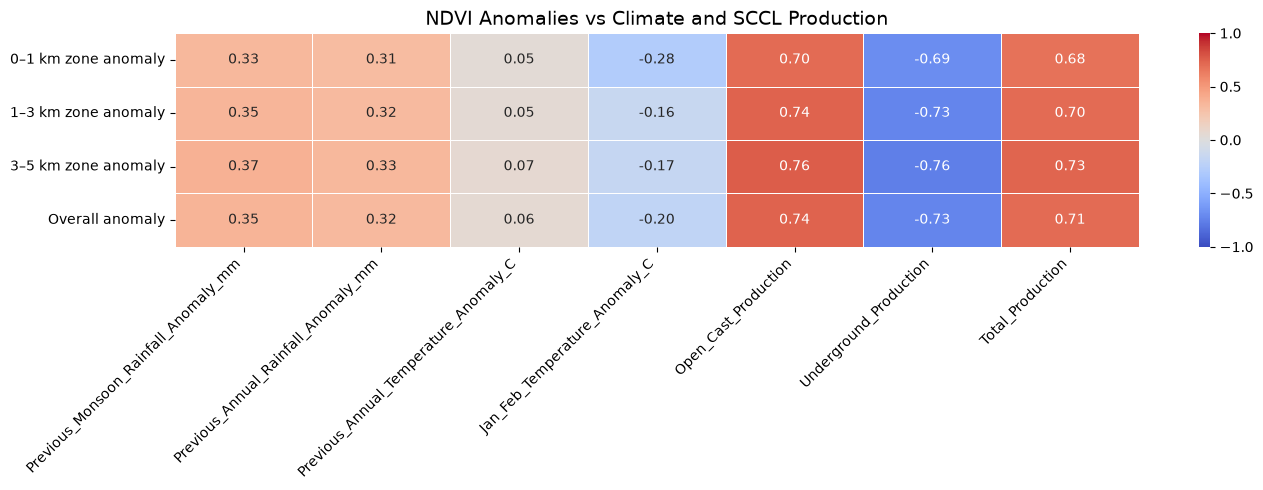


Analysis completed.
Saved:
1. Complete_Pearson_Correlation_Matrix.csv
2. Complete_Pearson_Correlation_Heatmap.png
3. NDVI_Climate_Mining_Correlations.csv
4. NDVI_Climate_Mining_Correlation_Heatmap.png


In [32]:

# ============================================================
# 5. FOCUS ON NDVI RELATIONSHIPS
# ============================================================

ndvi_variables = [
    "0–1 km zone anomaly",
    "1–3 km zone anomaly",
    "3–5 km zone anomaly",
    "Overall anomaly"
]

other_variables = [
    "Previous_Monsoon_Rainfall_Anomaly_mm",
    "Previous_Annual_Rainfall_Anomaly_mm",
    "Previous_Annual_Temperature_Anomaly_C",
    "Jan_Feb_Temperature_Anomaly_C",
    "Open_Cast_Production",
    "Underground_Production",
    "Total_Production"
]

ndvi_correlation = correlation_matrix.loc[
    ndvi_variables, other_variables
]

print("\nNDVI vs CLIMATE AND MINING CORRELATIONS:")
print(ndvi_correlation.round(3).to_string())

ndvi_correlation.to_csv(
    "NDVI_Climate_Mining_Correlations.csv"
)

plt.figure(figsize=(14, 5))

sns.heatmap(
    ndvi_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title(
    "NDVI Anomalies vs Climate and SCCL Production",
    fontsize=14
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "NDVI_Climate_Mining_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nAnalysis completed.")
print("Saved:")
print("1. Complete_Pearson_Correlation_Matrix.csv")
print("2. Complete_Pearson_Correlation_Heatmap.png")
print("3. NDVI_Climate_Mining_Correlations.csv")
print("4. NDVI_Climate_Mining_Correlation_Heatmap.png")

In [33]:

import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# 1. Load your combined dataset
df = pd.read_csv("NDVI_Climate_SCCL_Merged.csv")

# 2. Select numerical indicators for correlation
# Exclude Year because it is an identifier, not an indicator.
indicators = df.select_dtypes(include="number").drop(
    columns=["Year"], errors="ignore"
)

# 3. Calculate Spearman correlation coefficients
spearman_corr = indicators.corr(method="spearman")

print("SPEARMAN CORRELATION MATRIX")
print(spearman_corr.round(3))

# 4. Calculate p-values for every pair of indicators
columns = indicators.columns
p_values = pd.DataFrame(
    np.nan, index=columns, columns=columns
)

for col1 in columns:
    for col2 in columns:
        pair = indicators[[col1, col2]].dropna()

        if len(pair) >= 3:
            rho, p = spearmanr(pair[col1], pair[col2])
            p_values.loc[col1, col2] = p

print("\nSPEARMAN P-VALUE MATRIX")
print(p_values.round(4))

# 5. Save both matrices
spearman_corr.to_csv("Spearman_Correlation_Matrix.csv")
p_values.to_csv("Spearman_P_Value_Matrix.csv")

print("\nFiles saved successfully.")


SPEARMAN CORRELATION MATRIX
                                       0–1 km zone anomaly  \
0–1 km zone anomaly                                  1.000   
1–3 km zone anomaly                                  0.948   
3–5 km zone anomaly                                  0.942   
Overall anomaly                                      0.962   
Previous_Monsoon_Rainfall_Anomaly_mm                 0.261   
Previous_Annual_Rainfall_Anomaly_mm                  0.245   
Previous_Annual_Temperature_Anomaly_C                0.105   
Jan_Feb_Temperature_Anomaly_C                       -0.295   
Open_Cast_Production                                 0.718   
Underground_Production                              -0.747   
Total_Production                                     0.653   

                                       1–3 km zone anomaly  \
0–1 km zone anomaly                                  0.948   
1–3 km zone anomaly                                  1.000   
3–5 km zone anomaly                      

ValueError: setting an array element with a sequence.